# Conquest · חקירת נתונים (EDA) · אבן דרך 2

**הבעיה:** במשחק Conquest סטודנטים כובשים שטחים בעזרת תשובות על שאלות. כדי שהמשחק יהיה מאתגר ולא מתסכל, צריך להתאים שאלות לכל שחקן, ולכן אנחנו רוצים לדעת **מה הסיכוי ששחקן יענה נכון על שאלה**.

**ה-y:** `correct` (1 = ענה נכון בניסיון הראשון, 0 = שגוי). זה משתנה בינארי, כלומר בעיית סיווג.

**מקור הנתונים:** [ASSISTments 2009-2010 Skill Builder](https://sites.google.com/site/assistmentsdata/home/2009-2010-assistment-data/skill-builder-data-2009-2010) (הגרסה המתוקנת): ניסיונות מענה של תלמידי בית ספר בתרגול מתמטיקה. אחרי ניקוי: `data/assistments_clean.csv`. זה בסיס התחלתי, ובמהלך המשחק נאסוף נתונים משלנו (`data/attempts.jsonl`) שיחליפו אותו בהדרגה. פרטים מלאים ב-README.

**המחברת עונה על ארבע שאלות:** (1) סוגי העמודות, (2) איכות הנתונים, (3) התפלגויות (במיוחד של ה-y), (4) קשר בין העמודות ל-y, כולל בדיקת דליפה. בסוף: בדיקת סיגנל, תובנה ו-baseline.

*הערה: כותרות הגרפים באנגלית, כי matplotlib מציג עברית בצורה הפוכה. המסקנות מתחת לכל גרף בעברית.*

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 11,
})
GOLD, TEAL, RED, GREEN, GRAY = "#d9901a", "#14b8a6", "#f0616d", "#34d399", "#8f9bc7"

DATA = Path("data/assistments_clean.csv")
if not DATA.exists():  # when the notebook is opened from another folder
    DATA = Path("..") / DATA
df = pd.read_csv(DATA, dtype={"skill_id": str})
print(df.shape)
df.head()

(269196, 10)


,user_id,problem_id,skill_id,skill_name,answer_type,response_sec,hint_count,attempt_count,opportunity,correct
0,64525,51424,1_13,Box and Whisker,algebra,32.45,0,1,1,1
1,64525,51435,1_13,Box and Whisker,algebra,4.92,0,1,2,1
2,70363,51444,1_13,Box and Whisker,algebra,25.39,0,2,1,0
3,70363,51395,1_13,Box and Whisker,algebra,4.86,0,1,2,1
4,70363,51481,1_15,Box and Whisker,algebra,19.81,3,14,3,0


## שאלה 1: מה סוגי העמודות?

In [2]:
roles = {
    "user_id": "מזהה תלמיד (לא קלט למודל)",
    "problem_id": "מזהה שאלה (לא קלט למודל)",
    "skill_id": "קטגוריה: הנושא",
    "skill_name": "קטגוריה: שם הנושא",
    "answer_type": "קטגוריה: סוג השאלה",
    "response_sec": "מספר רציף: זמן תגובה בשניות",
    "hint_count": "מספר שלם: רמזים שנתבקשו (חשד לדליפה)",
    "attempt_count": "מספר שלם: ניסיונות עד תשובה (חשד לדליפה)",
    "opportunity": "מספר שלם: הניסיון ה-N של התלמיד באותו נושא",
    "correct": "היעד y: בינארי",
}
types = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique values": df.nunique(),
    "role": pd.Series(roles),
})
types

,dtype,unique values,role
user_id,int64,4148,מזהה תלמיד (לא קלט למודל)
problem_id,int64,16852,מזהה שאלה (לא קלט למודל)
skill_id,str,138,קטגוריה: הנושא
skill_name,str,101,קטגוריה: שם הנושא
answer_type,str,5,קטגוריה: סוג השאלה
response_sec,float64,21372,מספר רציף: זמן תגובה בשניות
hint_count,int64,8,מספר שלם: רמזים שנתבקשו (חשד לדליפה)
attempt_count,int64,178,מספר שלם: ניסיונות עד תשובה (חשד לדליפה)
opportunity,int64,738,מספר שלם: הניסיון ה-N של התלמיד באותו נושא
correct,int64,2,היעד y: בינארי


**מסקנה:** יש 10 עמודות. עמודת היעד `correct` בינארית. שלוש עמודות הן קטגוריות (`skill_id`, `skill_name`, `answer_type`), ארבע הן מספריות (`response_sec`, `hint_count`, `attempt_count`, `opportunity`), ושתיים הן מזהים (`user_id`, `problem_id`). המזהים נשמרים כמספרים, אבל הם לא כמותיים, ולכן אסור לחשב עליהם ממוצע או קורלציה ואסור להזין אותם למודל. `skill_id` ו-`skill_name` מתארות שתיהן את הנושא, אבל הן לא זהות: יש 138 מזהים ורק 101 שמות. 43 מזהים הם צירופים של כמה נושאים (כמו `1_13`, כ-17% מהשורות), ול-22 שמות יש יותר ממזהה אחד. במודל נשתמש רק באחת מהן כדי לא לכפול מידע, ובחרנו ב-`skill_id` כי הוא מבחין גם בשאלות שמשלבות כמה נושאים. שתי עמודות הספירה `hint_count` ו-`attempt_count` חשודות בדליפה, ונבדוק אותן בשאלה 4.

## שאלה 2: מה איכות הנתונים?

In [3]:
quality = pd.DataFrame({"missing": df.isna().sum(), "missing %": (df.isna().mean() * 100).round(2)})
print(quality.T.to_string())
print()
print("duplicate rows:", df.duplicated().sum())
print("duplicate (user, problem) pairs:", df.duplicated(["user_id", "problem_id"]).sum())
print("rows with attempt_count == 0:", (df["attempt_count"] == 0).sum())
df[["response_sec", "hint_count", "attempt_count", "opportunity"]].describe().round(2)

           user_id  problem_id  skill_id  skill_name  answer_type  response_sec  hint_count  attempt_count  opportunity  correct
missing        0.0         0.0       0.0         0.0          0.0           0.0         0.0            0.0          0.0      0.0
missing %      0.0         0.0       0.0         0.0          0.0           0.0         0.0            0.0          0.0      0.0

duplicate rows: 0
duplicate (user, problem) pairs: 0
rows with attempt_count == 0: 6536


,response_sec,hint_count,attempt_count,opportunity
count,269196.00,269196.00,269196.00,269196.00
mean,38.82,0.43,1.60,14.42
std,56.39,1.14,13.21,57.00
min,0.00,0.00,0.00,1.00
25%,9.07,0.00,1.00,3.00
50%,19.82,0.00,1.00,7.00
75%,44.33,0.00,1.00,14.00
max,599.88,7.00,3824.00,3371.00


**מסקנה:** בקובץ הנקי אין ערכים חסרים ואין כפילויות. מה שנוקה לפני כן (מהקובץ המקורי של 346,860 שורות) מוצג בגרף הבא. נשארו כמה ערכים חשודים שלא הסרנו: ל-6,536 שורות יש `attempt_count` שווה לאפס, וזה לא הגיוני: רק 6.1% מהן נכונות, ורק ב-3.2% מהן התבקש רמז, כך שהרמזים לא מסבירים אותן. ייתכן שאלה שאלות שנפתחו ולא נענו ונרשמו כשגויות. בנוסף יש שורה עם `attempt_count` של 3,824. השארנו אותם כי הם מעטים מאוד ביחס ל-269 אלף שורות, אבל נזכור אותם כשנבנה מודל.

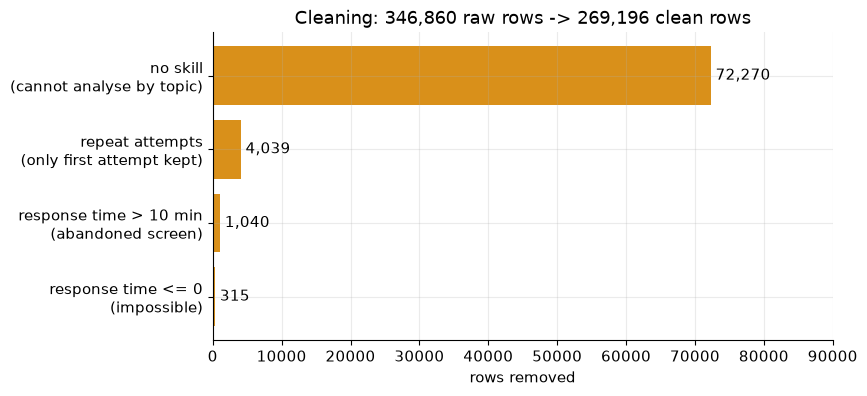

In [4]:
# What the cleaning script (data_prep.py) removed from the raw file, taken from its printed log.
removed = {
    "no skill\n(cannot analyse by topic)": 72270,
    "repeat attempts\n(only first attempt kept)": 4039,
    "response time > 10 min\n(abandoned screen)": 1040,
    "response time <= 0\n(impossible)": 315,
}
fig, ax = plt.subplots()
ax.barh(list(removed), list(removed.values()), color=GOLD)
ax.invert_yaxis()
ax.set_xlabel("rows removed")
ax.set_title("Cleaning: 346,860 raw rows -> 269,196 clean rows")
for i, v in enumerate(removed.values()):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlim(0, 90000)
plt.show()

**מסקנה:** רוב השורות שהוסרו (72,270, כ-21% מהקובץ) הן שורות ללא נושא. הסרנו אותן ולא מילאנו ערך, כי אין דרך לנחש נושא, ובלעדיו אי אפשר לנתח לפי נושא. שאר הניקויים קטנים וממוקדים: זמני תגובה לא הגיוניים וניסיונות חוזרים (השארנו רק את הראשון, כי ה-y הוא הצלחה בניסיון הראשון). נשארו 269,196 שורות, הרבה מעל המינימום של 300.

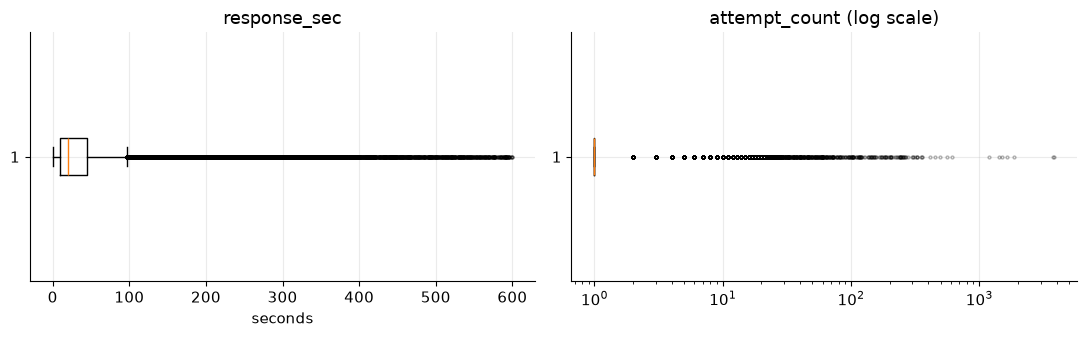

response_sec: median 19.8s, 90th pct 91s, 99th pct 293s, max 600s
share above the IQR whisker: 9.0%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].boxplot(df["response_sec"], orientation="horizontal", showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
axes[0].set_title("response_sec")
axes[0].set_xlabel("seconds")
axes[1].boxplot(df["attempt_count"], orientation="horizontal", flierprops={"markersize": 2, "alpha": 0.3})
axes[1].set_xscale("log")
axes[1].set_title("attempt_count (log scale)")
plt.tight_layout()
plt.show()
q1, q3 = df["response_sec"].quantile([0.25, 0.75])
print(f"response_sec: median {df['response_sec'].median():.1f}s, 90th pct {df['response_sec'].quantile(.9):.0f}s, "
      f"99th pct {df['response_sec'].quantile(.99):.0f}s, max {df['response_sec'].max():.0f}s")
print(f"share above the IQR whisker: {(df['response_sec'] > q3 + 1.5 * (q3 - q1)).mean():.1%}")

**מסקנה:** זמן התגובה מוטה מאוד ימינה: החציון 19.8 שניות, אבל אחד מכל עשרה עונה אחרי יותר מ-91 שניות, והמקסימום 600 שניות (תקרת הניקוי). כ-9% מהערכים נמצאים מעל הגבול העליון של כלל ה-IQR (Q3 + 1.5·IQR), כלומר נחשבים חריגים. אלה זמנים אמיתיים של תלמידים איטיים ולא טעויות, ולכן השארנו אותם, אבל במודל כדאי להשתמש בלוגריתם של הזמן או בקבוצות זמן. ב-`attempt_count` יש ערכים קיצוניים עד אלפים, והם ריאליים פחות. במודל נחתוך אותם או נתעלם מהעמודה.

## שאלה 3: מה ההתפלגויות? (במיוחד של עמודת התשובה)

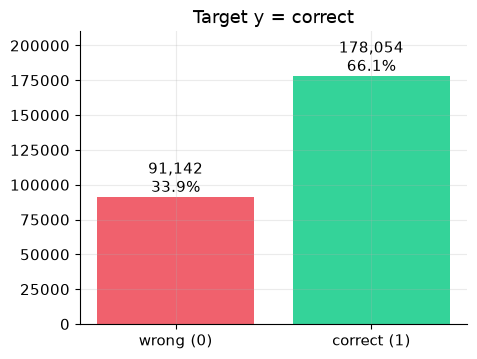

In [6]:
counts = df["correct"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.8))
bars = ax.bar(["wrong (0)", "correct (1)"], counts.values, color=[RED, GREEN])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n{v / len(df):.1%}", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Target y = correct")
plt.show()

**מסקנה:** היעד אינו מאוזן לגמרי: 66.1% תשובות נכונות מול 33.9% שגויות. הבעיה מתאימה לסיווג בינארי, והחלוקה לא קיצונית, ולכן אין צורך באיזון מלאכותי. זה גם קובע את ה-baseline: חיזוי של "נכון" תמיד יצדק ב-66.1% מהמקרים. אם מודל מגיע לדיוק דומה, הוא לא למד כלום, ולכן מדד הדיוק לבדו לא מספיק ונשתמש גם ב-AUC.

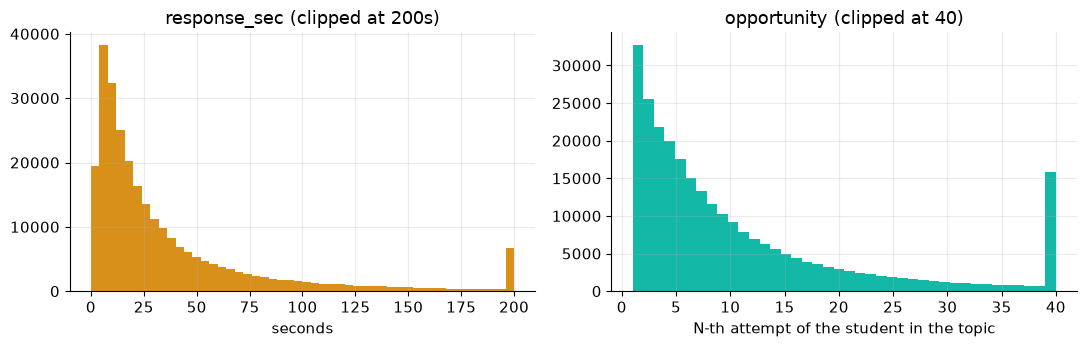

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df["response_sec"].clip(upper=200), bins=50, color=GOLD)
axes[0].set_title("response_sec (clipped at 200s)")
axes[0].set_xlabel("seconds")
axes[1].hist(df["opportunity"].clip(upper=40), bins=40, color=TEAL)
axes[1].set_title("opportunity (clipped at 40)")
axes[1].set_xlabel("N-th attempt of the student in the topic")
plt.tight_layout()
plt.show()

**מסקנה:** שני המשתנים המספריים מוטים ימינה עם זנב ארוך: רוב התשובות מהירות (עד כחצי דקה) ורוב השחקנים נמצאים בניסיונות הראשונים בנושא (חציון 7). מעטים פותרים הרבה מאוד תרגילים באותו נושא. בגלל הזנב נשתמש בחיתוך או בלוגריתם, ולא בממוצע, כדי לתאר אותם.

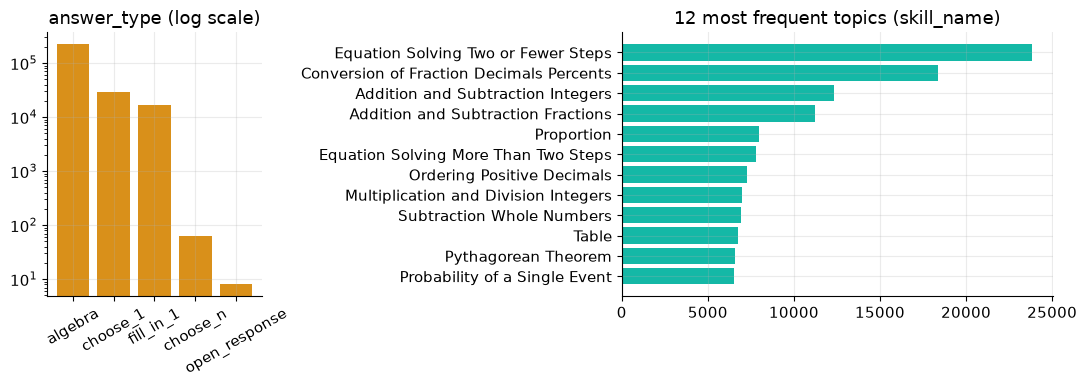

answer_type
algebra          222569
choose_1          29624
fill_in_1         16932
choose_n             63
open_response         8
distinct skill_id: 138 | distinct skill_name: 101


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2]})
at = df["answer_type"].value_counts()
axes[0].bar(at.index, at.values, color=GOLD)
axes[0].set_yscale("log")
axes[0].set_title("answer_type (log scale)")
axes[0].tick_params(axis="x", rotation=30)
top = df["skill_name"].value_counts().head(12)
axes[1].barh(top.index, top.values, color=TEAL)
axes[1].invert_yaxis()
axes[1].set_title("12 most frequent topics (skill_name)")
plt.tight_layout()
plt.show()
print(at.to_string())
print("distinct skill_id:", df["skill_id"].nunique(), "| distinct skill_name:", df["skill_name"].nunique())

**מסקנה:** סוג השאלה לא מאוזן: 83% הן שאלות מסוג `algebra` (הקלדת ביטוי), 11% בחירה מרשימה, 6% מילוי חופשי, ולשני הסוגים האחרים יש 63 ו-8 שורות בלבד, שאי אפשר ללמוד מהן. גם הנושאים לא מאוזנים: הנושא השכיח ביותר (`Equation Solving Two or Fewer Steps`) מכסה כ-9% מהנתונים, ויש הרבה נושאים נדירים. למודל יהיה קל ללמוד את הנושאים השכיחים וקשה את הנדירים.

## שאלה 4: מה הקשר בין העמודות ל-y? (כולל בדיקת דליפה)

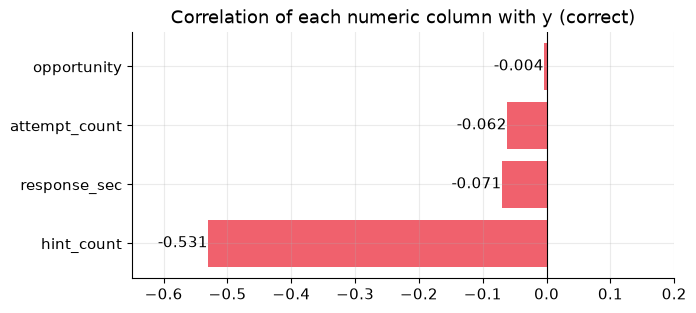

In [9]:
numeric = ["response_sec", "hint_count", "attempt_count", "opportunity"]
corr = df[numeric].corrwith(df["correct"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(corr.index, corr.values, color=[RED if v < 0 else GREEN for v in corr.values])
ax.axvline(0, color="black", lw=0.8)
for i, v in enumerate(corr.values):
    ax.text(v, i, f" {v:+.3f}", va="center", ha="left" if v >= 0 else "right")
ax.set_xlim(-0.65, 0.2)
ax.set_title("Correlation of each numeric column with y (correct)")
plt.show()

**מסקנה:** `hint_count` היא העמודה היחידה עם קורלציה חזקה ל-y (-0.53). שאר העמודות כמעט לא קשורות ליעד בקשר לינארי: `response_sec` (-0.07), `attempt_count` (-0.06) ו-`opportunity` (-0.00). אבל קורלציה לינארית יכולה להסתיר קשר לא ישר, ובגרף הבא נראה שלזמן התגובה יש קשר חזק שאינו לינארי. הקורלציה החזקה של `hint_count` חשודה מדי, ובדיקת הדליפה מטה מסבירה אותה.

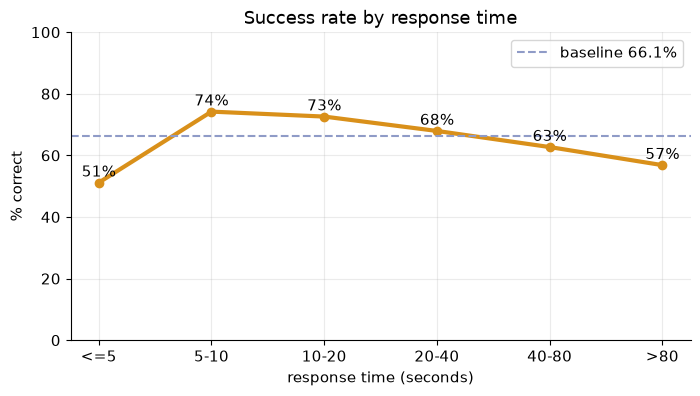

In [10]:
order = ["<=5", "5-10", "10-20", "20-40", "40-80", ">80"]
df["time_group"] = pd.cut(df["response_sec"], [0, 5, 10, 20, 40, 80, 600], labels=order)
by_time = df.groupby("time_group", observed=True)["correct"].mean() * 100
base = df["correct"].mean() * 100
fig, ax = plt.subplots()
ax.plot(by_time.index.astype(str), by_time.values, marker="o", color=GOLD, lw=3)
ax.axhline(base, color=GRAY, ls="--", label=f"baseline {base:.1f}%")
for x, v in zip(by_time.index.astype(str), by_time.values):
    ax.text(x, v + 2, f"{v:.0f}%", ha="center")
ax.set_ylim(0, 100)
ax.set_xlabel("response time (seconds)")
ax.set_ylabel("% correct")
ax.set_title("Success rate by response time")
ax.legend()
plt.show()

**מסקנה (התובנה העיקרית שלנו):** הקשר בין זמן התגובה להצלחה אינו ישר, ולכן הקורלציה הלינארית קטנה. תשובה מהירה מאוד (עד 5 שניות) נכונה רק ב-51% מהמקרים, כמעט כמו ניחוש. הטווח הטוב הוא 5-10 שניות (74%), ומעבר לזה ההצלחה יורדת בהדרגה עד 57% אחרי 80 שניות. כלומר זמן תגובה מנבא הצלחה, אבל דרך קבוצות או טרנספורמציה, ולא כמשתנה לינארי.

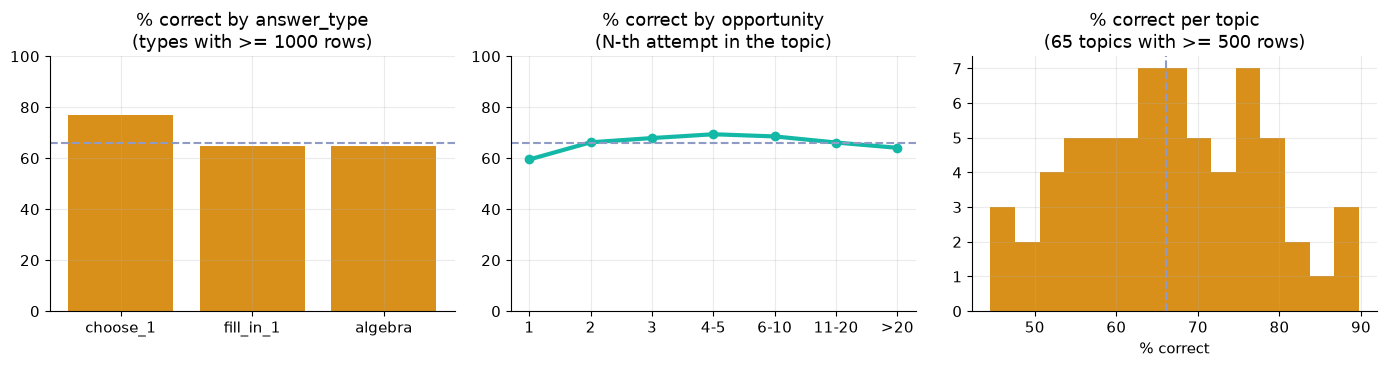

topics: from 44.6% to 89.7% correct


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

# by answer type (types with enough rows)
at = df.groupby("answer_type")["correct"].agg(["mean", "size"])
at = at[at["size"] >= 1000].sort_values("mean", ascending=False)
axes[0].bar(at.index, at["mean"] * 100, color=GOLD)
axes[0].set_title("% correct by answer_type\n(types with >= 1000 rows)")
axes[0].set_ylim(0, 100)
axes[0].axhline(base, color=GRAY, ls="--")

# by opportunity
opp = df.assign(o=pd.cut(df["opportunity"], [0, 1, 2, 3, 5, 10, 20, 100000],
                         labels=["1", "2", "3", "4-5", "6-10", "11-20", ">20"]))
op = opp.groupby("o", observed=True)["correct"].mean() * 100
axes[1].plot(op.index.astype(str), op.values, marker="o", color=TEAL, lw=3)
axes[1].set_title("% correct by opportunity\n(N-th attempt in the topic)")
axes[1].set_ylim(0, 100)
axes[1].axhline(base, color=GRAY, ls="--")

# topic spread
sk = df.groupby("skill_name")["correct"].agg(["mean", "size"])
sk = sk[sk["size"] >= 500]["mean"] * 100
axes[2].hist(sk, bins=15, color=GOLD)
axes[2].set_title(f"% correct per topic\n({len(sk)} topics with >= 500 rows)")
axes[2].set_xlabel("% correct")
axes[2].axvline(base, color=GRAY, ls="--")
plt.tight_layout()
plt.show()
print(f"topics: from {sk.min():.1f}% to {sk.max():.1f}% correct")

**מסקנה:** (1) שאלות בחירה מרשימה (`choose_1`) מצליחות יותר (77%) משאלות הקלדה (65%), כנראה כי אפשר לנחש. (2) הניסיון הראשון בנושא הוא הקשה ביותר (59.5% הצלחה). ההצלחה עולה עד 69.4% בניסיונות 4-5, ואחר כך יורדת בהדרגה ל-64.1% אחרי יותר מ-20 ניסיונות, כנראה כי מי שמתרגל נושא כל כך הרבה פעמים הוא מי שמתקשה בו. כלומר חזרה עוזרת בהתחלה, אבל הקשר לא ישר, ולכן הקורלציה הלינארית כמעט אפס. (3) הכי חזק: הנושא עצמו. ב-65 הנושאים עם לפחות 500 שורות ההצלחה נעה בין 44.6% ל-89.7%, כלומר נושא הוא משתנה מנבא חשוב.

### בדיקת דליפה (leakage)

דליפה היא עמודה שמכילה מידע על התוצאה שנודע רק **אחרי** שהתלמיד ענה. מודל שמשתמש בה נראה מצוין בנתונים, אבל לא יוכל לעבוד במשחק, כי שם המידע הזה לא קיים לפני התשובה. החשודות: `hint_count` ו-`attempt_count`.

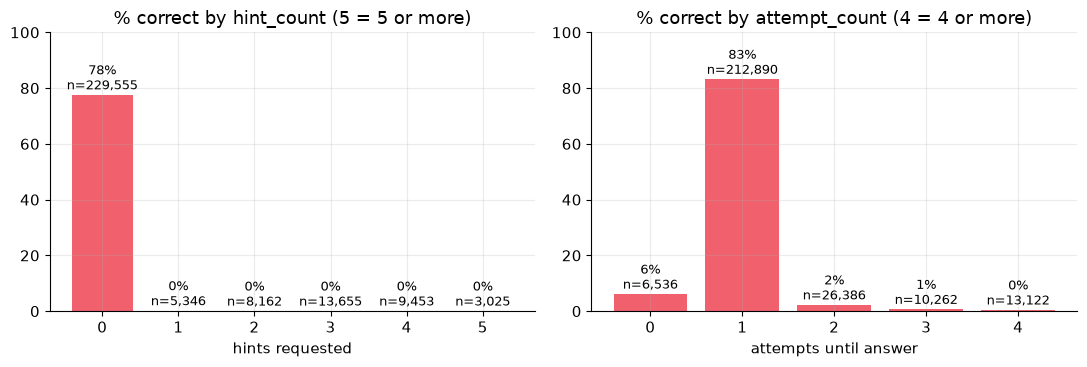

share of rows with at least one hint: 14.7%


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

hint = df.assign(h=df["hint_count"].clip(upper=5)).groupby("h")["correct"].agg(["mean", "size"])
axes[0].bar(hint.index.astype(str), hint["mean"] * 100, color=RED)
axes[0].set_title("% correct by hint_count (5 = 5 or more)")
axes[0].set_xlabel("hints requested")
axes[0].set_ylim(0, 100)
for i, (m, n) in enumerate(zip(hint["mean"], hint["size"])):
    axes[0].text(i, m * 100 + 2, f"{m:.0%}\nn={n:,}", ha="center", fontsize=9)

att = df.assign(a=df["attempt_count"].clip(upper=4)).groupby("a")["correct"].agg(["mean", "size"])
axes[1].bar(att.index.astype(str), att["mean"] * 100, color=RED)
axes[1].set_title("% correct by attempt_count (4 = 4 or more)")
axes[1].set_xlabel("attempts until answer")
axes[1].set_ylim(0, 100)
for i, (m, n) in enumerate(zip(att["mean"], att["size"])):
    axes[1].text(i, m * 100 + 2, f"{m:.0%}\nn={n:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()
print("share of rows with at least one hint:", f"{(df['hint_count'] > 0).mean():.1%}")

**מסקנה: שתי העמודות דולפות ולא נשתמש בהן כקלט.** מי שביקש לפחות רמז אחד נכשל כמעט תמיד (בין 0% ל-0.1% הצלחה, בכ-15% מהשורות), לעומת 77.6% הצלחה למי שלא ביקש. הסיבה: במערכת, בקשת רמז נרשמת אוטומטית כתשובה שגויה. גם `attempt_count` דולפת: כשהוא גדול מ-1, התלמיד כבר טעה בניסיון הראשון, ולכן ה-y הוא 1 רק בכ-1.4% מהמקרים. הקורלציה של -0.53 ל-`hint_count` שראינו קודם אינה סיגנל אמיתי, והיא אפילו מטעה. הקלט של המודל יהיה רק מידע שידוע לפני התשובה: נושא, סוג שאלה והניסיון ה-N בנושא. זמן התגובה נמדד בזמן המענה, ולכן שימושי רק אם נחזה אחרי תחילת השאלה, וזה שיקול שנחליט עליו ב-M3.

## בדיקת סיגנל: האם אפשר לחזות את ה-y?

כדי לוודא שיש בנתונים קשר שמודל יכול ללמוד, ניסינו מודל פשוט (רגרסיה לוגיסטית). חילקנו לאימון ולבדיקה **לפי תלמיד**, כך שתלמיד שהמודל ראה באימון לא מופיע בבדיקה (חלוקה לפי שורות הייתה מנפחת את התוצאות). זו בדיקה בלבד ולא המודל של M3.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

d = df.copy()
d["log_sec"] = np.log1p(d["response_sec"])
d["opp"] = d["opportunity"].clip(upper=30)
d["fast"] = (d["response_sec"] <= 5).astype(int)   # from the insight: very fast answers are guesses

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(d, groups=d["user_id"]))
train, test = d.iloc[train_idx], d.iloc[test_idx]
test_baseline = max(test["correct"].mean(), 1 - test["correct"].mean())


def evaluate(categorical, numeric):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
                             ("num", StandardScaler(), numeric)])
    model = make_pipeline(pre, LogisticRegression(max_iter=300))
    model.fit(train, train["correct"])
    p = model.predict_proba(test)[:, 1]
    return accuracy_score(test["correct"], p > 0.5), roc_auc_score(test["correct"], p)


experiments = {
    "baseline (always 'correct')": None,
    "topic only": (["skill_id"], []),
    "topic + log(time) + opportunity": (["skill_id"], ["log_sec", "opp"]),
    "topic + time + opportunity + 'fast' flag": (["skill_id"], ["log_sec", "opp", "fast"]),
    "WITH LEAKAGE (+ hint_count, attempt_count)": (["skill_id"], ["log_sec", "opp", "hint_count", "attempt_count"]),
}
rows = []
for name, spec in experiments.items():
    if spec is None:
        rows.append((name, test_baseline, 0.5))
    else:
        rows.append((name, *evaluate(*spec)))
results = pd.DataFrame(rows, columns=["model", "accuracy", "AUC"]).set_index("model")
print(f"train rows: {len(train):,} | test rows: {len(test):,} | test students: {test['user_id'].nunique():,}")
results.round(3)

train rows: 206,703 | test rows: 62,493 | test students: 1,037


,accuracy,AUC
model,,
baseline (always 'correct'),0.654,0.500
topic only,0.666,0.630
topic + log(time) + opportunity,0.667,0.631
topic + time + opportunity + 'fast' flag,0.675,0.653
"WITH LEAKAGE (+ hint_count, attempt_count)",0.882,0.894


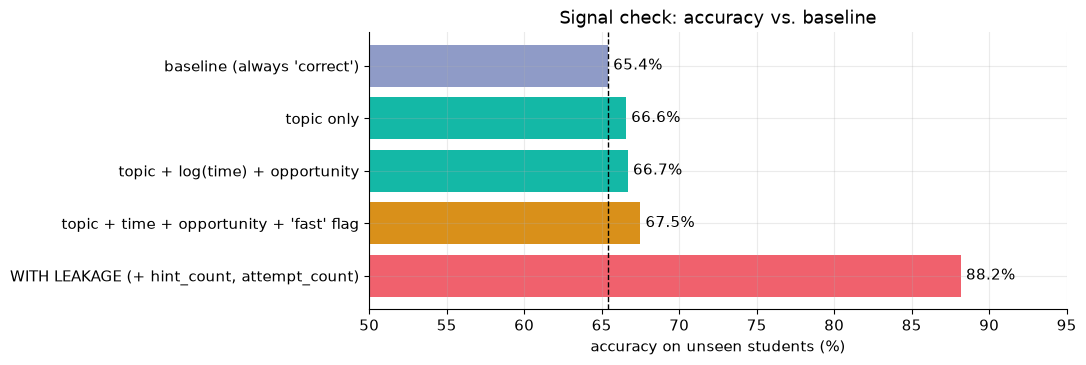

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [GRAY, TEAL, TEAL, GOLD, RED]
ax.barh(results.index, results["accuracy"] * 100, color=colors)
ax.invert_yaxis()
ax.set_xlim(50, 95)
ax.axvline(test_baseline * 100, color="black", ls="--", lw=1)
for i, v in enumerate(results["accuracy"] * 100):
    ax.text(v, i, f" {v:.1f}%", va="center")
ax.set_xlabel("accuracy on unseen students (%)")
ax.set_title("Signal check: accuracy vs. baseline")
plt.show()

**מסקנה:** יש סיגנל, אבל מתון. ה-baseline על קבוצת הבדיקה הוא 65.4% (הוא קצת שונה מ-66.1% כי זו קבוצת תלמידים אחרת). הנושא בלבד מעלה את הדיוק ל-66.6% ואת ה-AUC ל-0.63, ובעזרת תובנת זמן התגובה (דגל "מהיר מאוד") מגיעים ל-67.5% ו-AUC של 0.65. כלומר שיפור של כשתי נקודות אחוז מעל ה-baseline, וזה אמיתי אבל קטן. שימו לב שהתוצאה הטובה ביותר מניחה שזמן התגובה ידוע בזמן החיזוי. בלי זמן התגובה (נושא בלבד) השיפור הוא כנקודת אחוז אחת בלבד, ולכן ההחלטה שהשארנו ל-M3 בבדיקת הדליפה, אם לחזות לפני השאלה או במהלכה, משפיעה ישירות על הדיוק. גם `answer_type`, שציינו כקלט אפשרי, עוד לא נבדק כאן, ונוסיף אותו ב-M3. לעומת זאת, בהוספת העמודות הדולפות הדיוק קופץ ל-88% ו-AUC ל-0.89, וזו בדיוק הסיבה שאסור להשתמש בהן: ההצלחה המדומה הזו לא תתקיים במשחק. ל-M3 נדרש אפוא לשפר את המודל, למשל עם מאפייני שחקן (היסטוריית הצלחה בנושא), ואלה בדיוק הנתונים שנאסוף במשחק.

## תובנה ו-baseline

In [15]:
majority = max(df["correct"].mean(), 1 - df["correct"].mean())
print(f"BASELINE (always predict the majority class 'correct'): {majority:.1%} accuracy on all {len(df):,} rows")
print(f"On the unseen-students test set: {test_baseline:.1%}")
print()
print("INSIGHT: success is not linear in response time. "
      f"<=5s: {by_time.iloc[0]:.0f}% | 5-10s: {by_time.iloc[1]:.0f}% | >80s: {by_time.iloc[-1]:.0f}%")

BASELINE (always predict the majority class 'correct'): 66.1% accuracy on all 269,196 rows
On the unseen-students test set: 65.4%

INSIGHT: success is not linear in response time. <=5s: 51% | 5-10s: 74% | >80s: 57%


**תובנה:** גילינו שהקשר בין זמן התגובה להצלחה אינו ישר. תשובה מהירה מאוד (עד 5 שניות) נכונה רק ב-51% מהמקרים (כמעט ניחוש), הטווח הטוב הוא 5-10 שניות (74%), ומי שמתעכב מעל 80 שניות מצליח רק ב-57%. במשחק אפשר לזהות מהזמן שחקן שמנחש או שתקוע ולהציע לו רמז או שאלה אחרת.

**baseline:** תמיד לחזות "נכון". הדיוק: **66.1%** על כל הנתונים (65.4% על קבוצת הבדיקה). זה המספר ש-M3 צריך לנצח, ועל מודל טוב לעבור אותו בהרבה יותר משתי נקודות האחוז שקיבלנו בבדיקת הסיגנל.

**חשוב לזכור:** הנתונים הם מתמטיקה של תלמידי בית ספר, ולא מדעי המחשב בעברית, ולכן המודל לומד דפוסי מענה כלליים ולא תוכן של שאלות. את הפער הזה נסגור בנתוני המשחק עצמו.